# Thí nghiệm Random Forest – bộ feature sạch, target `log1p(SalePrice)` (Ames Housing)

**Mục tiêu:** so sánh với Random Forest đầu tiên của An (`baseline/baseline.ipynb`).

| | RF đầu tiên của An | Thí nghiệm này |
|---|---|---|
| Feature | `processed/` (146 cột, từ 35 feature gốc đã chọn) | **toàn bộ feature sạch trừ `Id`** (80 feature gốc, 288 cột sau mã hóa) |
| Target | `log1p(SalePrice)` | `log1p(SalePrice)` |
| Tham số | mặc định, không đặt `random_state` | mặc định, `random_state` được đặt |
| Chia dữ liệu | 80/20, seed 42 | giống hệt (có kiểm tra) |

Vì RF có yếu tố ngẫu nhiên và điểm của An chạy không đặt seed, notebook **chạy lại cấu hình của An với nhiều seed** để biết điểm của An dao động bao nhiêu, rồi mới so với feature sạch.

## Params

In [1]:
RANDOM_STATE = 42
TEST_SIZE = 0.2
CV_FOLDS = 5
SEEDS = [0, 1, 2, 3, 4]

# Điểm của An ghi trong baseline/baseline.ipynb (RF mặc định, tập valid 292 dòng, RMSE tính bằng USD)
AN_RF_VALID_RMSE = 27713
AN_RF_KAGGLE = 0.16285

## import thư viện

In [2]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

sns.set_theme(style="whitegrid")
Path("figures").mkdir(exist_ok=True)

## Đọc dữ liệu

Hai bộ feature, cùng một phép chia train/valid:
* **Bộ sạch:** `cleaned_data.csv` bỏ `Id`. Đọc với `keep_default_na=False` vì nhãn `None` (ví dụ `MasVnrType`) sẽ bị hiểu nhầm là thiếu.
* **Bộ của An:** `processed/X_train.csv`, `X_test.csv` (đã tiền xử lý ở `pre.ipynb`).

In [3]:
df = pd.read_csv("data/cleaned_data.csv", keep_default_na=False, na_values=[""])
ids = df["Id"]
df = df.drop(columns="Id")
print(df.shape, "| NaN còn lại:", int(df.isna().sum().sum()))

X = df.drop(columns="SalePrice")
y = df["SalePrice"]              # USD; log1p chỉ áp lúc huấn luyện

X_train, X_valid, y_train, y_valid, id_train, id_valid = train_test_split(
    X, y, ids, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
y_train_log = np.log1p(y_train)

# bộ feature của An
proc = Path("../../../data/processed")
Xp_train, Xp_valid = pd.read_csv(proc / "X_train.csv"), pd.read_csv(proc / "X_test.csv")
assert (y_train.values == pd.read_csv(proc / "y_train.csv")["SalePrice"].values).all()
assert (y_valid.values == pd.read_csv(proc / "y_test.csv")["SalePrice"].values).all()

print("Bộ sạch :", X_train.shape, X_valid.shape)
print("Bộ An   :", Xp_train.shape, Xp_valid.shape)
print("Hai bộ cùng một phép chia train/valid: OK")

(1458, 81) | NaN còn lại: 0
Bộ sạch : (1166, 80) (292, 80)
Bộ An   : (1166, 146) (292, 146)
Hai bộ cùng một phép chia train/valid: OK


## Mã hóa cột phân loại cho bộ sạch

Giống thí nghiệm Decision Tree: Ordinal cho 9 cột chất lượng (`Po < Fa < TA < Gd < Ex`), One-Hot cho các cột phân loại còn lại (kể cả `MSSubClass`, `MoSold`), cột số giữ nguyên, không scale.

In [4]:
quality = ["Po", "Fa", "TA", "Gd", "Ex"]
ORDINAL = {
    "ExterQual": quality, "ExterCond": quality, "KitchenQual": quality, "HeatingQC": quality,
    "BsmtQual": ["No Basement"] + quality, "BsmtCond": ["No Basement"] + quality,
    "GarageQual": ["No Garage"] + quality, "GarageCond": ["No Garage"] + quality,
    "FireplaceQu": ["No Fireplace"] + quality,
}
ordinal_cols = list(ORDINAL)
nominal_cols = [c for c in X.select_dtypes(exclude="number").columns if c not in ORDINAL] + ["MSSubClass", "MoSold"]
numeric_cols = [c for c in X.columns if c not in ordinal_cols + nominal_cols]

for col, order in ORDINAL.items():
    unseen = set(X[col].unique()) - set(order)
    assert not unseen, (col, unseen)


def make_clean_rf(seed, **rf_params):
    encoder = ColumnTransformer(
        [
            ("ordinal", OrdinalEncoder(categories=[ORDINAL[c] for c in ordinal_cols],
                                       handle_unknown="use_encoded_value", unknown_value=-1), ordinal_cols),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_cols),
            ("numeric", "passthrough", numeric_cols),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")
    return Pipeline([("encoder", encoder), ("rf", RandomForestRegressor(random_state=seed, **rf_params))])


def make_an_rf(seed):
    return RandomForestRegressor(random_state=seed)      # đúng cấu hình của An, chỉ thêm seed

## Cách chấm điểm

Mô hình học trên `log1p(SalePrice)`, dự đoán được đổi về USD bằng `expm1`:
* **RMSE (USD)**: chỉ số An dùng trong baseline.
* **RMSLE**: chỉ số Kaggle dùng, chính là RMSE trên thang log.
* MAE và R² tính trên USD.

In [5]:
def evaluate(y_true, pred_log):
    pred = np.expm1(pred_log)
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, pred)),
        "MAE": mean_absolute_error(y_true, pred),
        "R2": r2_score(y_true, pred),
        "RMSLE": np.sqrt(mean_squared_error(np.log1p(y_true), pred_log)),
    }

## Run 1 – RF mặc định trên bộ feature sạch (seed 42)

In [6]:
run1 = make_clean_rf(RANDOM_STATE).fit(X_train, y_train_log)
p1_train, p1_valid = run1.predict(X_train), run1.predict(X_valid)

print("Số cột sau mã hóa:", run1.named_steps["encoder"].get_feature_names_out().size)
res1 = pd.DataFrame({"train": evaluate(y_train, p1_train), "valid": evaluate(y_valid, p1_valid)}).T
res1.round({"RMSE": 0, "MAE": 0, "R2": 4, "RMSLE": 4})

Số cột sau mã hóa: 288


,RMSE,MAE,R2,RMSLE
train,11019.0,6542.0,0.9814,0.0531
valid,23992.0,16502.0,0.8958,0.1426


**Nhận xét:**
- RF mặc định trên bộ feature sạch (seed 42) cho RMSE valid **23.992 USD**, MAE 16.502 USD, R² 0,8958 và RMSLE 0,1426.
- Vẫn còn overfitting nhẹ: RMSLE train 0,0531, thấp hơn nhiều so với valid 0,1426. Dù vậy điểm valid tốt hơn hẳn một cây đơn lẻ (Decision Tree trước đó có RMSE valid 38.299 USD, tuy khác cách xử lý target nên chỉ để tham khảo).

## Run 2 – Chạy lại RF của An (feature `processed/`, seed 42)

Kiểm tra xem cấu hình của An có tái lập được con số 27.713 hay không.

In [7]:
run2 = make_an_rf(RANDOM_STATE).fit(Xp_train, y_train_log)
p2_train, p2_valid = run2.predict(Xp_train), run2.predict(Xp_valid)

res2 = pd.DataFrame({"train": evaluate(y_train, p2_train), "valid": evaluate(y_valid, p2_valid)}).T
print(f"Điểm An ghi trong baseline.ipynb: RMSE valid = {AN_RF_VALID_RMSE:,}")
res2.round({"RMSE": 0, "MAE": 0, "R2": 4, "RMSLE": 4})

Điểm An ghi trong baseline.ipynb: RMSE valid = 27,713


,RMSE,MAE,R2,RMSLE
train,12027.0,7290.0,0.9778,0.0581
valid,27083.0,18772.0,0.8672,0.1560


**Nhận xét:**
- Chạy lại đúng cấu hình của An (feature `processed/`, mặc định, seed 42) cho RMSE valid **27.083 USD** và RMSLE 0,1560.
- Con số An ghi (27.713 USD) lệch 630 USD (khoảng 2,3%) so với lần chạy lại. Chênh lệch này nằm trong độ dao động do RF không đặt seed (xem Run 3: 27.045 đến 27.737), nên **cấu hình của An tái lập được** và điểm của An là hợp lệ.

## Run 3 – Độ dao động theo seed

RF của An không đặt seed nên mỗi lần chạy cho một điểm khác. Chạy cả hai bộ feature với 5 seed để xem chênh lệch giữa hai bộ có lớn hơn độ dao động này hay không.

In [8]:
rows = []
for seed in SEEDS:
    clean = make_clean_rf(seed).fit(X_train, y_train_log)
    an = make_an_rf(seed).fit(Xp_train, y_train_log)
    for name, pred in [("Bộ sạch (80 feature)", clean.predict(X_valid)), ("Bộ của An (35 feature)", an.predict(Xp_valid))]:
        r = evaluate(y_valid, pred)
        rows.append({"seed": seed, "bộ feature": name, "RMSE": r["RMSE"], "RMSLE": r["RMSLE"], "R2": r["R2"]})

seeds_df = pd.DataFrame(rows)
seed_summary = seeds_df.groupby("bộ feature")[["RMSE", "RMSLE", "R2"]].agg(["mean", "std", "min", "max"])
seed_summary.round(4)

RMSE                                     RMSLE  \
                              mean       std         min         max    mean   
bộ feature                                                                     
Bộ của An (35 feature)  27333.2581  273.7514  27045.2701  27736.8718  0.1552   
Bộ sạch (80 feature)    24389.2490  222.3768  24155.2821  24634.7625  0.1434   

                                                    R2                          
                           std     min     max    mean     std     min     max  
bộ feature                                                                      
Bộ của An (35 feature)  0.0016  0.1531  0.1569  0.8647  0.0027  0.8607  0.8676  
Bộ sạch (80 feature)    0.0009  0.1424  0.1446  0.8923  0.0020  0.8901  0.8944

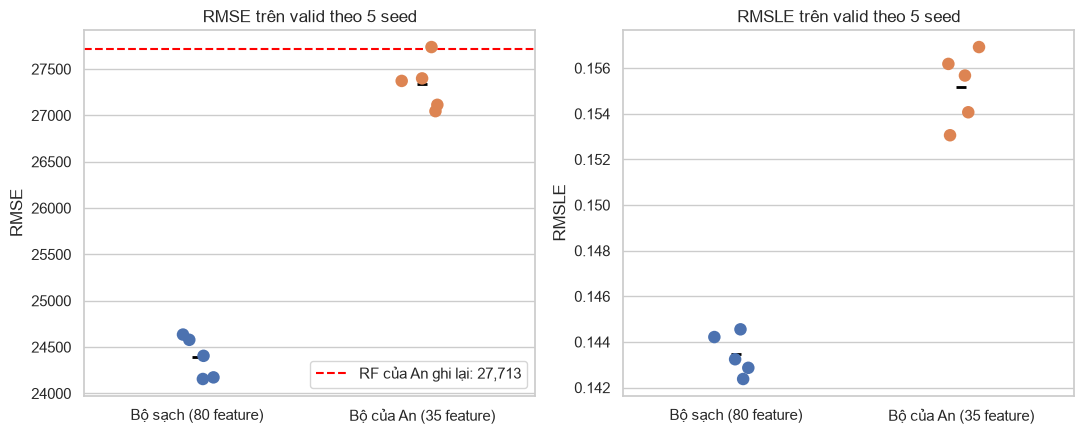

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, metric, an_value in [(axes[0], "RMSE", AN_RF_VALID_RMSE), (axes[1], "RMSLE", None)]:
    sns.stripplot(data=seeds_df, x="bộ feature", y=metric, hue="bộ feature", s=9, ax=ax, legend=False)
    sns.pointplot(data=seeds_df, x="bộ feature", y=metric, linestyle="none", color="black", markers="_", errorbar=None, ax=ax)
    if an_value:
        ax.axhline(an_value, color="red", linestyle="--", label=f"RF của An ghi lại: {an_value:,}")
        ax.legend()
    ax.set_title(f"{metric} trên valid theo 5 seed")
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig("figures/random_forest_seed_compare.png", dpi=150)
plt.show()

**Nhận xét:**
- Bộ của An: RMSE valid trung bình **27.333 USD** (độ lệch chuẩn 274, từ 27.045 đến 27.737). Bộ sạch: **24.389 USD** (độ lệch chuẩn 222, từ 24.155 đến 24.635).
- Hai khoảng dao động **không chồng nhau**: chênh trung bình khoảng 2.944 USD (khoảng 10,8%), gấp hơn 10 lần độ lệch chuẩn theo seed. RMSLE cũng vậy (0,1552 so với 0,1434). Điểm 27.713 của An nằm đúng trong khoảng dao động của bộ An.
- Lưu ý: độ dao động này chỉ phản ánh tính ngẫu nhiên của mô hình, chưa phản ánh việc chọn cách chia train/valid khác.

## Run 4 – Cross-validation 5-fold trên tập train

Tập valid chỉ có 292 dòng nên so sánh thêm bằng CV trên 1.166 dòng train (điểm là RMSLE, vì CV chạy trực tiếp trên thang log).

In [10]:
cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

cv_clean = -cross_val_score(make_clean_rf(RANDOM_STATE), X_train, y_train_log, cv=cv, scoring="neg_root_mean_squared_error")
cv_an = -cross_val_score(make_an_rf(RANDOM_STATE), Xp_train, y_train_log, cv=cv, scoring="neg_root_mean_squared_error")

cv_df = pd.DataFrame({"Bộ sạch (80 feature)": cv_clean, "Bộ của An (35 feature)": cv_an}, index=[f"fold {i + 1}" for i in range(CV_FOLDS)])
cv_df.loc["trung bình"] = cv_df.mean()
cv_df.loc["độ lệch chuẩn"] = cv_df.iloc[:CV_FOLDS].std()
cv_df.round(4)

,Bộ sạch (80 feature),Bộ của An (35 feature)
fold 1,0.1570,0.1741
fold 2,0.1398,0.1538
fold 3,0.1288,0.1420
fold 4,0.1303,0.1344
fold 5,0.1469,0.1583
trung bình,0.1406,0.1525
độ lệch chuẩn,0.0118,0.0153


**Nhận xét:**
- RMSLE CV trung bình: bộ sạch **0,1406**, bộ của An **0,1525**.
- Độ lệch chuẩn giữa các fold (0,012 đến 0,015) xấp xỉ chênh lệch trung bình (0,012), nên nếu chỉ nhìn trung bình thì chưa đủ chắc; tuy nhiên đây là so sánh trên cùng các fold và **bộ sạch thắng cả 5/5 fold** (chênh từ 0,004 đến 0,017). Kết quả cùng chiều với tập valid.
- Với bộ của An, CV chạy trên `X_train.csv` đã được tiền xử lý bằng bộ mã hóa fit sẵn trên toàn bộ train. Với cây quyết định (không dùng scale) ảnh hưởng này không đáng kể.

## Tổng hợp so sánh

In [11]:
clean_valid = evaluate(y_valid, p1_valid)
an_replica_valid = evaluate(y_valid, p2_valid)
s = seed_summary

compare = pd.DataFrame({
    "RF của An (điểm ghi lại)": {"RMSE valid": AN_RF_VALID_RMSE, "RMSLE valid": np.nan, "RMSLE CV": np.nan, "Kaggle": AN_RF_KAGGLE},
    "Chạy lại RF của An (seed 42)": {"RMSE valid": an_replica_valid["RMSE"], "RMSLE valid": an_replica_valid["RMSLE"], "RMSLE CV": cv_an.mean(), "Kaggle": np.nan},
    "RF bộ sạch (seed 42)": {"RMSE valid": clean_valid["RMSE"], "RMSLE valid": clean_valid["RMSLE"], "RMSLE CV": cv_clean.mean(), "Kaggle": np.nan},
}).T
compare["RMSE valid, TB 5 seed"] = [np.nan, s.loc["Bộ của An (35 feature)", ("RMSE", "mean")], s.loc["Bộ sạch (80 feature)", ("RMSE", "mean")]]
compare.round({"RMSE valid": 0, "RMSLE valid": 4, "RMSLE CV": 4, "Kaggle": 5, "RMSE valid, TB 5 seed": 0})

,RMSE valid,RMSLE valid,RMSLE CV,Kaggle,"RMSE valid, TB 5 seed"
RF của An (điểm ghi lại),27713.0,NaN,NaN,0.16285,NaN
Chạy lại RF của An (seed 42),27083.0,0.1560,0.1525,NaN,27333.0
RF bộ sạch (seed 42),23992.0,0.1426,0.1406,NaN,24389.0


**Nhận xét:** Cả ba thước đo đều cho cùng một hướng:

| Thước đo | RF của An (chạy lại) | RF bộ sạch |
|---|---|---|
| RMSE valid, seed 42 (USD) | 27.083 | 23.992 |
| RMSE valid, trung bình 5 seed (USD) | 27.333 | 24.389 |
| RMSLE valid, seed 42 | 0,1560 | 0,1426 |
| RMSLE CV 5-fold | 0,1525 | 0,1406 |

- Bộ sạch (80 feature, bỏ `Id`) giảm RMSE valid khoảng 10–11% so với RF đầu tiên của An (27.713 xuống khoảng 24.000–24.400 USD). Khác biệt vượt xa độ dao động theo seed.
- **Điểm Kaggle chưa đo được** vì mình chưa nộp. File dự đoán đã sẵn ở `data/submission_rf_clean_log1p.csv`. Tham khảo: điểm Kaggle của An (0,16285) cao hơn RMSLE valid chạy lại của An (0,1560) khoảng 0,007; nếu bộ sạch có độ lệch tương tự thì điểm Kaggle có thể quanh 0,15, nhưng đây chỉ là suy đoán cho tới khi nộp thật.

## Feature quan trọng và dự đoán so với thực tế (bộ sạch)

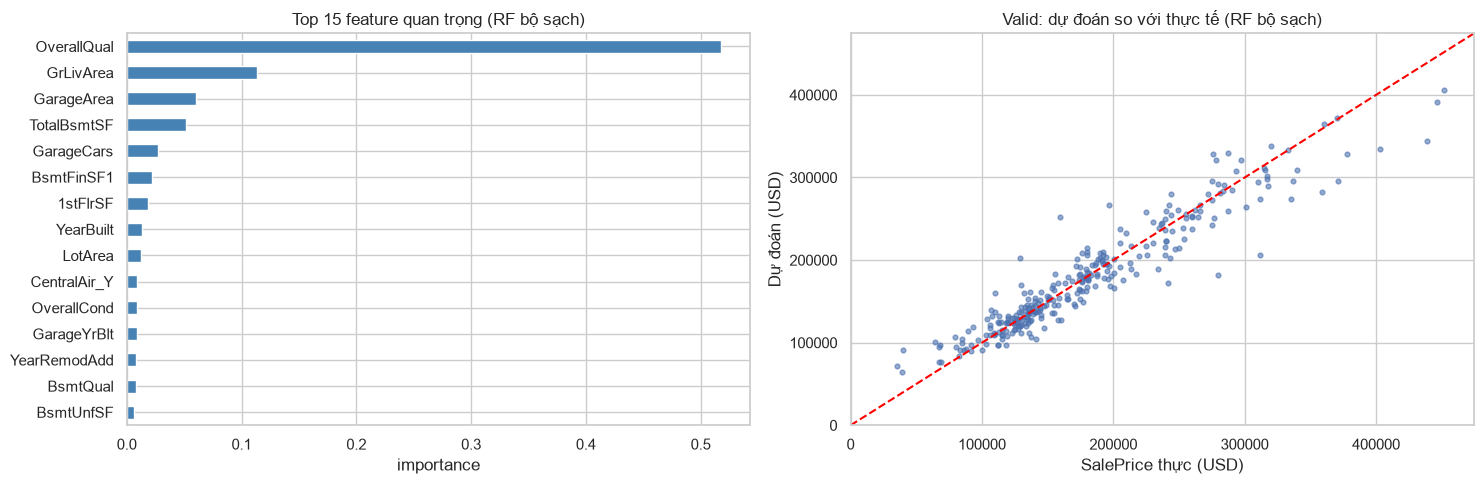

Top 5 của An: {'ord__ExterQual': 0.335, 'num__GrLivArea': 0.217, 'num__TotalBsmtSF': 0.092, 'num__GarageArea': 0.082, 'ord__KitchenQual': 0.042}


,importance
OverallQual,0.5173
GrLivArea,0.1135
GarageArea,0.0600
TotalBsmtSF,0.0517
GarageCars,0.0271
BsmtFinSF1,0.0220
1stFlrSF,0.0187
YearBuilt,0.0130
LotArea,0.0121
CentralAir_Y,0.0089


In [12]:
encoded_names = run1.named_steps["encoder"].get_feature_names_out()
importance = pd.Series(run1.named_steps["rf"].feature_importances_, index=encoded_names).sort_values(ascending=False)
an_importance = pd.Series(run2.feature_importances_, index=Xp_train.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
importance.head(15)[::-1].plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("Top 15 feature quan trọng (RF bộ sạch)")
axes[0].set_xlabel("importance")

pred_usd = np.expm1(p1_valid)
axes[1].scatter(y_valid, pred_usd, s=12, alpha=0.6)
lim = [0, max(y_valid.max(), pred_usd.max()) * 1.05]
axes[1].plot(lim, lim, color="red", linestyle="--")
axes[1].set_xlim(lim); axes[1].set_ylim(lim)
axes[1].set_xlabel("SalePrice thực (USD)"); axes[1].set_ylabel("Dự đoán (USD)")
axes[1].set_title("Valid: dự đoán so với thực tế (RF bộ sạch)")
plt.tight_layout()
plt.savefig("figures/random_forest_importance_pred.png", dpi=150)
plt.show()

print("Top 5 của An:", an_importance.head(5).round(3).to_dict())
importance.head(10).round(4).to_frame("importance")

**Nhận xét:**
- `OverallQual` chiếm 51,7% độ quan trọng, theo sau là `GrLivArea` (11,4%), `GarageArea` (6,0%), `TotalBsmtSF` (5,2%) và `GarageCars` (2,7%).
- Bộ feature của An **không có `OverallQual`** (cũng không có `YearBuilt`, `1stFlrSF`); trong RF của An, `ExterQual` (33,5%) là feature quan trọng nhất, có vẻ đóng vai trò thay thế. Vì vậy nhiều khả năng phần cải thiện đến từ việc bộ sạch có thêm `OverallQual` và các feature thời gian/diện tích khác. Suy luận này sau đó đã được kiểm chứng ở thí nghiệm `15-11-2026-Nguyen-rf-ablation-overallqual`: thêm riêng `OverallQual` vào bộ của An thu hồi khoảng 40–60% khoảng cách, còn bỏ riêng nó khỏi bộ sạch gần như không làm kém đi. Tức `OverallQual` đóng góp một phần đáng kể nhưng **không phải nguồn duy nhất** của cải thiện.
- Biểu đồ dự đoán bám sát đường chéo ở khoảng giá 80.000–300.000 USD; với nhà trên khoảng 350.000 USD, mô hình dự đoán thấp hơn thực tế (dự đoán cao nhất khoảng 407.000 USD trong khi giá thực cao nhất 451.950 USD) và có vài điểm sai lệch lớn.

# Lưu kết quả

Lưu tham số, model, dự đoán valid, file dự đoán cho Kaggle (huấn luyện trên `X_train` như RF của An, **chưa nộp nên chưa có điểm Kaggle**) và nhật ký Excel `Working_details_RandomForest_Clean_Log1p.xlsx`.

In [13]:
# 1. tham số của RF bộ sạch (Run 1)
params = run1.named_steps["rf"].get_params()
with open("random_forest_params.json", "w", encoding="utf-8") as f:
    json.dump(params, f, indent=4, ensure_ascii=False)

# 2. model (gồm bước mã hóa), nén để file gọn
joblib.dump(run1, "random_forest_model.pkl", compress=3)

# 3. dự đoán valid
pd.DataFrame({
    "Id": id_valid.values, "SalePrice": y_valid.values,
    "pred_rf_clean": np.expm1(p1_valid), "pred_rf_an_replica": np.expm1(p2_valid),
    "abs_error_rf_clean": np.abs(y_valid.values - np.expm1(p1_valid)),
}).to_csv("data/valid_predictions.csv", index=False)

# 4. dự đoán cho tập test Kaggle
test = pd.read_csv("data/cleaned_test.csv", keep_default_na=False, na_values=[""])
test_ids = test["Id"]
X_test = test.drop(columns="Id")[X.columns]
sample = pd.read_csv("../../../data/raw/sample_submission.csv")
assert (test_ids.values == sample["Id"].values).all()
assert X_test.isna().sum().sum() == 0
unknown_ordinal = {c: sorted(set(X_test[c]) - set(ORDINAL[c])) for c in ordinal_cols if set(X_test[c]) - set(ORDINAL[c])}
print("Giá trị ordinal lạ trong test (bị mã hóa -1):", unknown_ordinal or "không có")

sub = pd.DataFrame({"Id": test_ids, "SalePrice": np.expm1(run1.predict(X_test))})
assert sub["SalePrice"].notna().all() and (sub["SalePrice"] > 0).all()
sub.to_csv("data/submission_rf_clean_log1p.csv", index=False)
print("Submission:", sub.shape, "| min", round(sub.SalePrice.min()), "| max", round(sub.SalePrice.max()))

Giá trị ordinal lạ trong test (bị mã hóa -1): không có


Submission: (1459, 2) | min 60729 | max 600911


In [14]:
import zipfile
from xml.sax.saxutils import escape


def col_letter(i):
    s = ""
    i += 1
    while i:
        i, r = divmod(i - 1, 26)
        s = chr(65 + r) + s
    return s


def write_xlsx(path, sheet_name, rows, header_rows, widths):
    """Ghi 1 sheet Excel tối giản (chuỗi + số), header_rows là chỉ số dòng (0-based) cần in đậm."""
    xml_rows = []
    for r, row in enumerate(rows):
        cells = []
        for c, v in enumerate(row):
            if v is None or v == "":
                continue
            ref = f"{col_letter(c)}{r + 1}"
            style = ' s="1"' if r in header_rows else ""
            if isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool):
                cells.append(f'<c r="{ref}"{style}><v>{float(v)}</v></c>')
            else:
                cells.append(f'<c r="{ref}"{style} t="inlineStr"><is><t xml:space="preserve">{escape(str(v))}</t></is></c>')
        xml_rows.append(f'<row r="{r + 1}">{"".join(cells)}</row>')
    cols = "".join(f'<col min="{i + 1}" max="{i + 1}" width="{w}" customWidth="1"/>' for i, w in enumerate(widths))
    sheet = ('<?xml version="1.0" encoding="UTF-8" standalone="yes"?>'
             '<worksheet xmlns="http://schemas.openxmlformats.org/spreadsheetml/2006/main">'
             f'<cols>{cols}</cols><sheetData>{"".join(xml_rows)}</sheetData></worksheet>')
    styles = ('<?xml version="1.0" encoding="UTF-8" standalone="yes"?>'
              '<styleSheet xmlns="http://schemas.openxmlformats.org/spreadsheetml/2006/main">'
              '<fonts count="2"><font><sz val="11"/><name val="Calibri"/></font>'
              '<font><b/><sz val="11"/><name val="Calibri"/></font></fonts>'
              '<fills count="3"><fill><patternFill patternType="none"/></fill><fill><patternFill patternType="gray125"/></fill>'
              '<fill><patternFill patternType="solid"><fgColor rgb="FFD9E1F2"/></patternFill></fill></fills>'
              '<borders count="1"><border><left/><right/><top/><bottom/><diagonal/></border></borders>'
              '<cellStyleXfs count="1"><xf numFmtId="0" fontId="0" fillId="0" borderId="0"/></cellStyleXfs>'
              '<cellXfs count="2"><xf numFmtId="0" fontId="0" fillId="0" borderId="0" xfId="0"/>'
              '<xf numFmtId="0" fontId="1" fillId="2" borderId="0" xfId="0" applyFont="1" applyFill="1"/></cellXfs>'
              '</styleSheet>')
    files = {
        "[Content_Types].xml": '<?xml version="1.0" encoding="UTF-8" standalone="yes"?><Types xmlns="http://schemas.openxmlformats.org/package/2006/content-types"><Default Extension="rels" ContentType="application/vnd.openxmlformats-package.relationships+xml"/><Default Extension="xml" ContentType="application/xml"/><Override PartName="/xl/workbook.xml" ContentType="application/vnd.openxmlformats-officedocument.spreadsheetml.sheet.main+xml"/><Override PartName="/xl/worksheets/sheet1.xml" ContentType="application/vnd.openxmlformats-officedocument.spreadsheetml.worksheet+xml"/><Override PartName="/xl/styles.xml" ContentType="application/vnd.openxmlformats-officedocument.spreadsheetml.styles+xml"/></Types>',
        "_rels/.rels": '<?xml version="1.0" encoding="UTF-8" standalone="yes"?><Relationships xmlns="http://schemas.openxmlformats.org/package/2006/relationships"><Relationship Id="rId1" Type="http://schemas.openxmlformats.org/officeDocument/2006/relationships/officeDocument" Target="xl/workbook.xml"/></Relationships>',
        "xl/workbook.xml": f'<?xml version="1.0" encoding="UTF-8" standalone="yes"?><workbook xmlns="http://schemas.openxmlformats.org/spreadsheetml/2006/main" xmlns:r="http://schemas.openxmlformats.org/officeDocument/2006/relationships"><sheets><sheet name="{escape(sheet_name)}" sheetId="1" r:id="rId1"/></sheets></workbook>',
        "xl/_rels/workbook.xml.rels": '<?xml version="1.0" encoding="UTF-8" standalone="yes"?><Relationships xmlns="http://schemas.openxmlformats.org/package/2006/relationships"><Relationship Id="rId1" Type="http://schemas.openxmlformats.org/officeDocument/2006/relationships/worksheet" Target="worksheets/sheet1.xml"/><Relationship Id="rId2" Type="http://schemas.openxmlformats.org/officeDocument/2006/relationships/styles" Target="styles.xml"/></Relationships>',
        "xl/styles.xml": styles,
        "xl/worksheets/sheet1.xml": sheet,
    }
    with zipfile.ZipFile(path, "w", zipfile.ZIP_DEFLATED) as z:
        for name, content in files.items():
            z.writestr(name, content)

In [15]:
rows, headers = [], set()


def add(row, header=False):
    if header:
        headers.add(len(rows))
    rows.append(row)


def stat(name, col):
    return seed_summary.loc[name, col]


add(["THÍ NGHIỆM RANDOM FOREST — BỘ FEATURE SẠCH, TARGET log1p(SalePrice)"], header=True)
add(["Trạng thái", "Đã chạy; điểm tính trên tập valid tự chia. File submission đã tạo nhưng chưa nộp Kaggle"])
add([])
add(["Thiết lập", "Giá trị", "", "Tham số RF", "Giá trị"], header=True)
add(["Feature", "80 cột của cleaned_data.csv (bỏ Id)", "", "n_estimators", params["n_estimators"]])
add(["Target", "log1p(SalePrice), dự đoán đổi về USD bằng expm1", "", "max_depth", "None" if params["max_depth"] is None else params["max_depth"]])
add(["Mã hóa", "Ordinal (9 cột chất lượng) + One-Hot, không scale", "", "max_features", params["max_features"]])
add(["Chia dữ liệu", f"train {len(X_train)} / valid {len(X_valid)} (80/20, seed {RANDOM_STATE}), giống RF của An", "", "min_samples_leaf", params["min_samples_leaf"]])
add(["So sánh với", "RF của An: feature processed/ (35 feature gốc, 146 cột), tham số mặc định, không seed", "", "random_state", RANDOM_STATE])
add(["Số cột sau mã hóa", len(encoded_names), "", "Seed dùng ở Run 3", ", ".join(map(str, SEEDS))])
add([])
add(["1. So sánh tổng hợp"], header=True)
add(["Mô hình", "RMSE valid (USD)", "RMSLE valid", "RMSLE CV 5-fold", "RMSE valid, TB 5 seed", "Kaggle public"], header=True)
add(["RF của An (điểm ghi lại)", AN_RF_VALID_RMSE, "", "", "", AN_RF_KAGGLE])
add(["Chạy lại RF của An (seed 42)", round(an_replica_valid["RMSE"], 0), round(an_replica_valid["RMSLE"], 4), round(cv_an.mean(), 4),
     round(stat("Bộ của An (35 feature)", ("RMSE", "mean")), 0), ""])
add(["RF bộ sạch (seed 42)", round(clean_valid["RMSE"], 0), round(clean_valid["RMSLE"], 4), round(cv_clean.mean(), 4),
     round(stat("Bộ sạch (80 feature)", ("RMSE", "mean")), 0), "chưa nộp"])
add([])
add(["2. Độ dao động theo seed (valid)"], header=True)
add(["Bộ feature", "RMSE TB", "RMSE độ lệch chuẩn", "RMSE min", "RMSE max", "RMSLE TB"], header=True)
for name in ["Bộ của An (35 feature)", "Bộ sạch (80 feature)"]:
    add([name, round(stat(name, ("RMSE", "mean")), 0), round(stat(name, ("RMSE", "std")), 0), round(stat(name, ("RMSE", "min")), 0),
         round(stat(name, ("RMSE", "max")), 0), round(stat(name, ("RMSLE", "mean")), 4)])
add([])
add(["3. Điểm theo từng seed (valid)"], header=True)
add(["Seed", "Bộ feature", "RMSE", "RMSLE", "R2"], header=True)
for _, r in seeds_df.iterrows():
    add([int(r["seed"]), r["bộ feature"], round(r["RMSE"], 0), round(r["RMSLE"], 4), round(r["R2"], 4)])
add([])
add(["4. Cross-validation 5-fold (RMSLE trên train)"], header=True)
add(["", "Bộ sạch (80 feature)", "Bộ của An (35 feature)"], header=True)
for idx, r in cv_df.iterrows():
    add([idx, round(r["Bộ sạch (80 feature)"], 4), round(r["Bộ của An (35 feature)"], 4)])
add([])
add(["5. Top 10 feature quan trọng (RF bộ sạch)"], header=True)
add(["Feature", "Importance"], header=True)
for name, v in importance.head(10).items():
    add([name, round(float(v), 4)])

write_xlsx("Working_details_RandomForest_Clean_Log1p.xlsx", "RF_Clean_Log1p", rows, headers, [34, 44, 18, 22, 22, 16])
print("Đã ghi Working_details_RandomForest_Clean_Log1p.xlsx")

Đã ghi Working_details_RandomForest_Clean_Log1p.xlsx
